# Phase 1: Data

This notebook covers steps 1.2 to 1.5 of [`docs/01_project_plan.md`](../docs/01_project_plan.md). It checks the sample that `src/sample.py` produced and gathers the evidence for three cutoffs the team still has to sign off on:

| Step | Question | Feeds |
| --- | --- | --- |
| 1.2 | Does the training sample look like the full data? | Report: data & sampling |
| 1.3 | Where do we cap extreme watch ratios? | Model target (Act 1) |
| 1.4 | Above which watch ratio does a video count as "liked"? | Precision@10, nDCG@10 |
| 1.5 | Which category does each video get? | Diversity metric (Acts 2 and 3) |

**Ground rule (spec fix #2):** cutoffs are chosen on **train** and **validation** users only. The test users are not looked at here. Their only appearance is the row-count table in section 1, which `src/sample.py` already prints anyway.

**Before running:** `python scripts/download_data.py` and `python src/sample.py`. The notebook takes about a minute, most of it loading the full big matrix for the comparison.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
from sample import find_csv, load_matrix, check   # same cleaning as the sampler
from categories import load_categories

FIG_DIR = ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Chart style: one surface, muted ink, thin marks. Blue = full data, orange = our sample.
FULL, SAMPLE, MUTED = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "text.color": "#0b0b0b", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})
pd.set_option("display.float_format", "{:,.3f}".format)

def save(fig, name):
    fig.savefig(FIG_DIR / name)
    print(f"saved results/figures/{name}")

## 1. Load everything

- `train`, `val`, `test`: the three Parquet files from `src/sample.py`.
- `big`, `small`: the full matrices, cleaned **exactly** as the sampler cleans them (same `load_matrix` function: drop infinite ratios, average repeat watches). Otherwise the representativeness check would compare two differently cleaned datasets and partly measure the cleaning.
- `cats`: one first-level category per video, with English names (`src/categories.py`).

In [2]:
proc = ROOT / "data" / "processed"
train, val, test = (pd.read_parquet(proc / f"{n}.parquet") for n in ("train", "val", "test"))
big = load_matrix(find_csv("big_matrix.csv"))
small = load_matrix(find_csv("small_matrix.csv"))
cats = load_categories()

check(train, val, test)   # the sampler's leakage checks, re-run on the saved files

pd.DataFrame({
    name: {"rows": len(df), "users": df.user_id.nunique(), "videos": df.video_id.nunique()}
    for name, df in [("big (full)", big), ("small (full)", small),
                     ("train", train), ("val", val), ("test", test)]
}).T.style.format("{:,}")

  big_matrix.csv: 12,530,806 rows -> 10,300,969 unique (user, video) pairs


  small_matrix.csv: 4,676,570 rows -> 4,676,570 unique (user, video) pairs


,rows,users,videos
big (full),"10,300,969","7,176","10,728"
small (full),"4,676,570","1,411","3,327"
train,"997,794","1,254","9,833"
val,"994,409",300,"3,327"
test,"1,657,115",500,"3,327"


### A finding about the raw data: big and small matrices never overlap

`src/sample.py` reported **0** overlapping (user, video) pairs removed. Spec fix #3 expected many. The cell below shows why: KuaiRec's authors already held the small-matrix pairs out of the big matrix. For the 1,411 small-matrix users, the big matrix contains **no rows at all** on the 3,327 small-matrix videos.

What this means for us:

- Spec fix #3's **conclusion** (training keeps all videos) is correct, and more strongly than the plan says. With a "small-matrix videos only" filter, evaluation users would have exactly zero training rows, not just few.
- Its **stated reason** ("the leakage check removes those pairs") was wrong: there is nothing to remove. The plan and the sampler's docstring have been corrected. The leakage check stays as a safety net, which costs nothing.
- In the jargon, the small matrix is a clean **holdout set** by construction: the model is always graded on (user, video) pairs it has never seen.

In [3]:
small_users, small_videos = small.user_id.unique(), small.video_id.unique()
big_small_users = big[big.user_id.isin(small_users)]
print(f"(user, video) pairs in both matrices:          "
      f"{len(big.merge(small[['user_id', 'video_id']], on=['user_id', 'video_id'])):,}")
print(f"Big-matrix rows of small-matrix users:         {len(big_small_users):,}")
print(f"  ... of which on small-matrix videos:         {big_small_users.video_id.isin(small_videos).sum():,}")
print(f"Big-matrix rows of OTHER users on those videos: "
      f"{big[~big.user_id.isin(small_users)].video_id.isin(small_videos).sum():,}")

(user, video) pairs in both matrices:          0
Big-matrix rows of small-matrix users:         503,716
  ... of which on small-matrix videos:         0


Big-matrix rows of OTHER users on those videos: 8,321,501


## 2. Step 1.2: Is the sample representative?

**Representativeness** means the slice has the same shape as the whole, so conclusions drawn on the slice carry over. We compare the training sample with the full big matrix on three things:

1. the **watch ratio distribution** (what the model learns to predict),
2. the **share of views per category** (what the diversity story is about),
3. **user activity**, i.e. rows per user (how much history the model gets per person).

To put one number on "how different are two distributions", we use the **total variation distance (TVD)**: half the sum of absolute differences between the two sets of shares. It reads as "the share of mass you would have to move to turn one distribution into the other". 0 = identical, 1 = no overlap. As a rough rule, below 0.05 is close enough that nobody would notice on a chart.

In [4]:
def tvd(p, q):
    # Total variation distance between two share vectors (aligned on their index).
    p, q = p.align(q, fill_value=0)
    return 0.5 * (p - q).abs().sum()

bins = np.linspace(0, 5, 51)   # 0.1-wide bins. Ratios above 5 (<1% of rows) are counted in the last bin.
h_full = pd.Series(np.histogram(big.watch_ratio.clip(upper=5), bins)[0] / len(big))
h_train = pd.Series(np.histogram(train.watch_ratio.clip(upper=5), bins)[0] / len(train))

cat_of = cats.set_index("video_id").category
share_full = big.video_id.map(cat_of).value_counts(normalize=True)
share_train = train.video_id.map(cat_of).value_counts(normalize=True)

print(f"TVD watch ratio (0.1-wide bins): {tvd(h_full, h_train):.3f}")
print(f"TVD category share of views:     {tvd(share_full, share_train):.3f}")

pd.DataFrame({
    "full big matrix": big.watch_ratio.quantile([.5, .9, .99]).values,
    "train sample": train.watch_ratio.quantile([.5, .9, .99]).values,
}, index=["p50", "p90", "p99"])

TVD watch ratio (0.1-wide bins): 0.036
TVD category share of views:     0.043


,full big matrix,train sample
p50,0.743,0.776
p90,1.794,1.815
p99,4.792,4.286


saved results/figures/01_representativeness.png


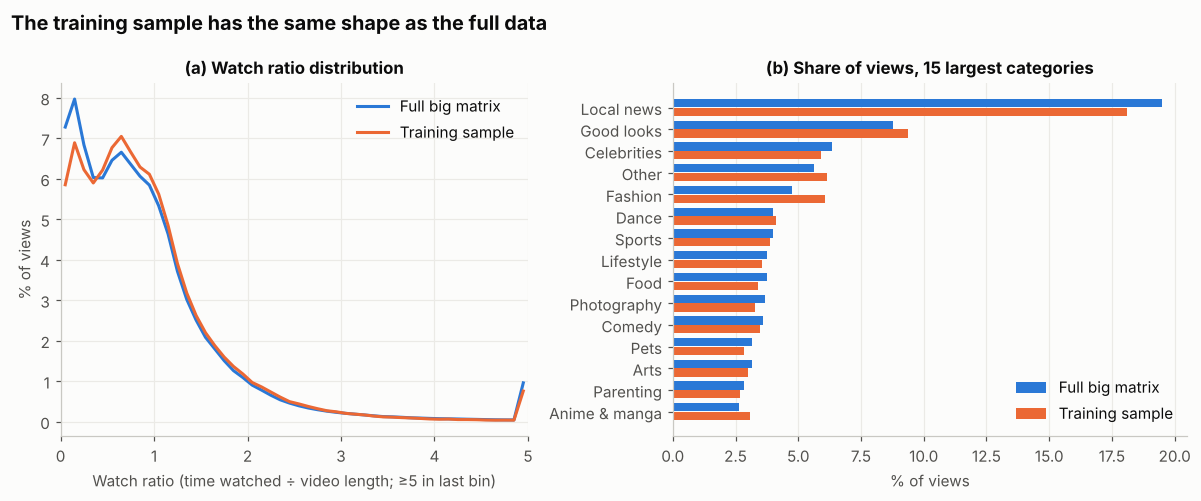

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1, 1.1]})

centers = (bins[:-1] + bins[1:]) / 2
ax1.plot(centers, h_full * 100, color=FULL, lw=2, label="Full big matrix")
ax1.plot(centers, h_train * 100, color=SAMPLE, lw=2, label="Training sample")
ax1.set(xlabel="Watch ratio (time watched ÷ video length; ≥5 in last bin)",
        ylabel="% of views", title="(a) Watch ratio distribution", xlim=(0, 5))
ax1.legend()

top = share_full.head(15).index[::-1]
y = np.arange(len(top))
ax2.barh(y + 0.2, share_full[top] * 100, height=0.38, color=FULL, label="Full big matrix")
ax2.barh(y - 0.2, share_train.reindex(top, fill_value=0) * 100, height=0.38, color=SAMPLE,
         label="Training sample")
ax2.set_yticks(y, top)
ax2.set(xlabel="% of views", title="(b) Share of views, 15 largest categories")
ax2.grid(axis="y", visible=False)
ax2.legend(loc="lower right")

fig.suptitle("The training sample has the same shape as the full data", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "01_representativeness.png")

**Reading the chart.** The category bars in (b) line up closely, and above a watch ratio of about 0.3 the two curves in (a) are nearly identical. Both TVDs are below 0.05. The sample is a fair miniature of the full data on the two things the project depends on.

**One visible gap:** the sample has fewer quick skips (watch ratio below 0.2) than the full data. That isn't a sampling accident. It's a side effect of spec fix #1: the evaluation users skip less than other users, and they make up 29% of training rows but only about 5% of the full big matrix. The cell below shows it. The effect on the model is small (it learns a slightly higher average watch ratio), but it's the honest answer if someone asks why the curves differ at the left edge.

In [6]:
eval_users = np.union1d(val.user_id.unique(), test.user_id.unique())
eval_rows = train.user_id.isin(eval_users)
pd.DataFrame({
    "% of views below 0.2": [(train.watch_ratio[eval_rows] < 0.2).mean() * 100,
                             (train.watch_ratio[~eval_rows] < 0.2).mean() * 100,
                             (big.watch_ratio < 0.2).mean() * 100],
    "% of rows in that set": [eval_rows.mean() * 100, (~eval_rows).mean() * 100, 100],
}, index=["train: evaluation users", "train: other users", "full big matrix"])

,% of views below 0.2,% of rows in that set
train: evaluation users,8.525,28.747
train: other users,14.439,71.253
full big matrix,15.245,100.000


### User activity: evaluation users have thinner histories

The other way the training sample is *not* a miniature, again on purpose. The 800 evaluation users (spec fix #1) are most of the 1,254 training users. Their big-matrix history is missing the 3,327 small-matrix videos (see section 1), so they have far fewer rows than other users.

In the chart, the left peak of the *full* data (around 300 rows) is the 1,411 small-matrix users themselves, for the same reason. The right peak is everyone else.

In [7]:
rows_per_user = train.groupby("user_id").size()
is_eval = rows_per_user.index.isin(eval_users)
activity = pd.DataFrame({
    "users": [is_eval.sum(), (~is_eval).sum(), big.user_id.nunique()],
    "share of train rows": [rows_per_user[is_eval].sum() / len(train),
                            rows_per_user[~is_eval].sum() / len(train), np.nan],
    "median rows per user": [rows_per_user[is_eval].median(), rows_per_user[~is_eval].median(),
                             big.groupby("user_id").size().median()],
}, index=["evaluation users (in train)", "other train users", "all users, full big matrix"])
activity

,users,share of train rows,median rows per user
evaluation users (in train),800,0.287,349.000
other train users,454,0.713,"1,712.000"
"all users, full big matrix",7176,NaN,"1,571.000"


saved results/figures/01_user_activity.png


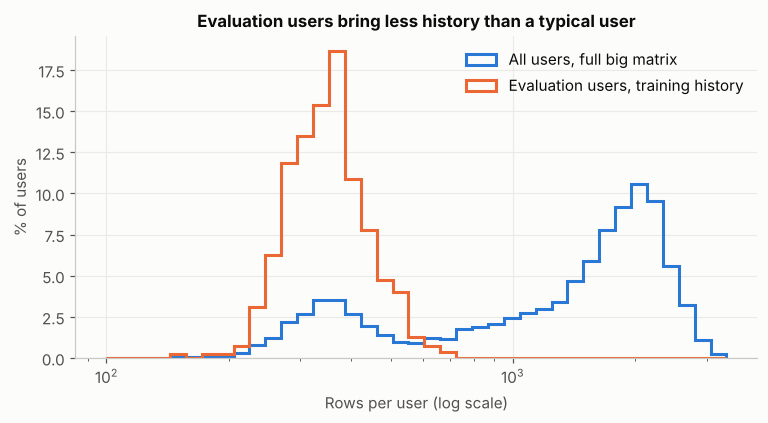

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.8))
edges = np.logspace(2, np.log10(rows_per_user.max() + 1), 40)
for counts, color, label in [(big.groupby("user_id").size(), FULL, "All users, full big matrix"),
                             (rows_per_user[is_eval], SAMPLE, "Evaluation users, training history")]:
    ax.hist(counts, edges, weights=np.full(len(counts), 100 / len(counts)), histtype="step",
            lw=2, color=color, label=label)
ax.set_xscale("log")
ax.set(xlabel="Rows per user (log scale)", ylabel="% of users",
       title="Evaluation users bring less history than a typical user")
ax.legend()
save(fig, "01_user_activity.png")

**Why this matters for Phase 2.** The model learns evaluation users' taste from a few hundred videos each, none of them from the test catalogue. That's a realistic setting (in production you also predict for videos a user has never seen), but it makes Act 1 harder than a random split would. If Act 1 results are weak, this is the first thing to look at, and the knob is `--train-rows`: it adds more *other* users, which teaches the model more about the small-matrix videos.

The 454 other users are where the model learns the small-matrix videos themselves (they are the only ones with rows on those videos). So the sampler's "at least half the row budget for other users" rule is doing real work.

## 3. Step 1.3: Outlier cap on the watch ratio

**Outliers** here are views like "watch ratio 40": a 10-second clip left looping while someone cooks dinner. Matrix factorization minimizes the *squared* error, so one view at 40 pulls on the model as hard as about 1,600 views that are each off by 1.0. A **cap** (also called **clipping** or **winsorizing**) sets every value above a threshold to the threshold. The view still counts as "watched it a lot", just not as 40 times.

The plan asks for a cap between 3 and 5, around the 99th **percentile** (the value below which 99% of rows fall). We pick it on the training data, because that's what the model sees.

In [9]:
pcts = [0.50, 0.90, 0.95, 0.99, 0.995, 0.999]
pd.DataFrame({"train watch ratio": train.watch_ratio.quantile(pcts).values},
             index=[f"p{p * 100:g}" for p in pcts]).T

,p50,p90,p95,p99,p99.5,p99.9
train watch ratio,0.776,1.815,2.320,4.286,6.041,15.665


In [10]:
wr = train.watch_ratio
pd.DataFrame([{
    "cap": c,
    "% of rows capped": (wr > c).mean() * 100,
    "mean before": wr.mean(),
    "mean after": wr.clip(upper=c).mean(),
    "std before": wr.std(),
    "std after": wr.clip(upper=c).std(),
} for c in [3, 4, 5]]).set_index("cap")

,% of rows capped,mean before,mean after,std before,std after
cap,,,,,
3,2.402,0.974,0.904,1.549,0.676
4,1.163,0.974,0.921,1.549,0.735
5,0.725,0.974,0.930,1.549,0.778


saved results/figures/01_watch_ratio_cap.png


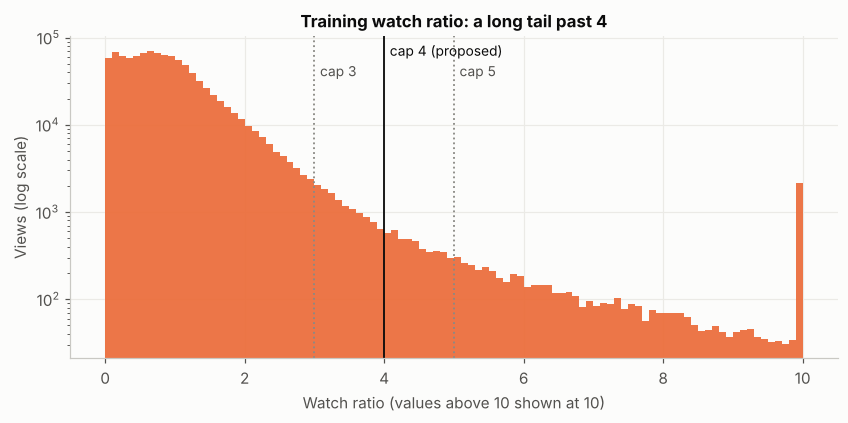

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.8))
edges = np.linspace(0, 10, 101)
ax.hist(wr.clip(upper=10), edges, color=SAMPLE, alpha=0.9)
ax.set_yscale("log")
for c, y in [(3, 0.35), (4, 0.6), (5, 0.35)]:
    proposed = c == 4
    ax.axvline(c, color="#0b0b0b" if proposed else MUTED, lw=1.2, ls="-" if proposed else ":")
    ax.text(c + 0.08, ax.get_ylim()[1] * y, f"cap {c}" + (" (proposed)" if proposed else ""),
            color="#0b0b0b" if proposed else "#52514e", fontsize=9)
ax.set(xlabel="Watch ratio (values above 10 shown at 10)", ylabel="Views (log scale)",
       title="Training watch ratio: a long tail past 4")
save(fig, "01_watch_ratio_cap.png")

**Proposal: cap at 4.0.**

- It sits right at the 99th percentile (≈4.3) and inside the plan's 3–5 range.
- It touches only about 1% of training rows, yet it roughly halves the standard deviation (1.55 → 0.74, see the table): that 1% of rows was carrying a big share of the variance. That's what outliers look like.
- Why not 3? It would cap twice as many rows (2.4%) and start flattening genuine "watched it three times" signal, for only a little less spread.
- 4.0 still keeps a clear gap above the relevance threshold (2.0, next section), so capping never changes whether a view counts as "liked".
- A round number is easier to defend in the Q&A than "4.29".

The cap is applied to the **model target** in `src/model.py`, not to the saved files (the sampler's docstring says the same). RMSE should be reported on capped values for both the model and the baseline, so the comparison is fair.

## 4. Step 1.4: Relevance threshold

Precision@10 and nDCG@10 need a yes/no answer: did the user *like* this video? We call a video **relevant** to a user when their watch ratio is at or above a **relevance threshold**. The proposal says 2.0 ("watched it twice"). The plan's warning: if only 1–2% of rows pass, Precision@10 is tiny for every model and hard to compare.

We measure this on the **validation users** (graded on the small matrix, like test users), not the test users.

A useful reference number: for a **random ranking**, the expected Precision@10 equals the share of relevant videos. So the "relevant share" column is also the floor any model must clear.

In [12]:
rows = []
for t in [1.0, 1.5, 2.0]:
    rel = val.watch_ratio >= t
    per_user = rel.groupby(val.user_id).sum()
    rows.append({
        "threshold": t,
        "% relevant (= random Precision@10)": rel.mean() * 100,
        "median relevant videos per user": per_user.median(),
        "users with < 10 relevant": (per_user < 10).mean() * 100,
        "users with 0 relevant": (per_user == 0).mean() * 100,
    })
thresholds = pd.DataFrame(rows).set_index("threshold")
thresholds

,% relevant (= random Precision@10),median relevant videos per user,users with < 10 relevant,users with 0 relevant
threshold,,,,
1.000,32.393,"1,045.000",0.000,0.000
1.500,11.127,305.500,0.000,0.000
2.000,4.664,83.000,1.000,0.000


saved results/figures/01_relevance_threshold.png


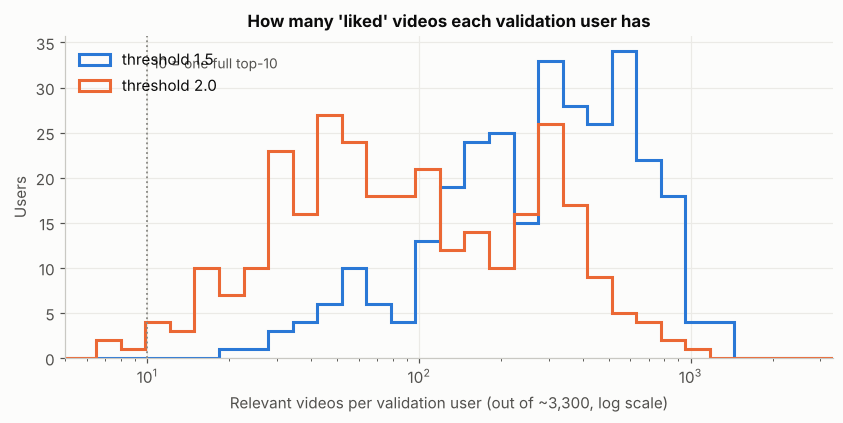

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for t, color, ls in [(1.5, FULL, "-"), (2.0, SAMPLE, "-")]:
    per_user = (val.watch_ratio >= t).groupby(val.user_id).sum()
    ax.hist(per_user, np.logspace(0, np.log10(3327), 40), histtype="step", lw=2, color=color,
            ls=ls, label=f"threshold {t}")
ax.axvline(10, color=MUTED, lw=1.2, ls=":")
ax.text(10.5, ax.get_ylim()[1] * 0.9, "10 = one full top-10", color="#52514e", fontsize=9)
ax.set_xscale("log")
ax.set_xlim(5, 3327)
ax.set(xlabel="Relevant videos per validation user (out of ~3,300, log scale)", ylabel="Users",
       title="How many 'liked' videos each validation user has")
ax.legend(loc="upper left")
save(fig, "01_relevance_threshold.png")

**Proposal: keep 2.0.**

- About 4–5% of validation rows pass, comfortably above the plan's 1–2% danger zone. A random ranking scores about 0.05 Precision@10, which leaves plenty of room for the model to show it beats both random and popularity.
- The density of the small matrix helps a lot here: each user has rated ~3,300 videos, so even 2.5% is ~80 liked videos per user. In a sparse dataset the same percentage would leave most users with no positives at all.
- **The weak spot is small:** no validation user has zero relevant videos, and only about 1% have fewer than 10 (so even a perfect model couldn't fill their top 10 with liked videos). The spread is wide, though, from under 10 to over 1,000 per user, so per-user Precision@10 will vary a lot. Report the average across users with that in mind.
- **Fallback:** 1.5 if Phase 2 shows all models bunched together near the floor. It triples the number of positives, but "watched one and a half times" is a weaker story than "watched it twice".

## 5. Step 1.5: One category per video

The diversity metric is "number of different categories in the top 10", so every video needs exactly one category. The options from the plan:

1. **First-level category** from `kuairec_caption_category.csv`: one per video, 37 named categories plus "Other" and "Unknown". *(Recommended in the plan.)*
2. **First tag** in `item_categories.csv`: tags are numeric ids; 16% of videos have several.
3. **All tags**: precise, harder to explain.

First, are options 1 and 2 even different?

In [14]:
import ast

tags = pd.read_csv(find_csv("item_categories.csv"))
tags["tags"] = tags.feat.map(ast.literal_eval)
tags = tags.merge(cats, on="video_id")
print("Tags per video:", tags.tags.str.len().value_counts().sort_index().to_dict())
print(f"First tag == first-level category id: {(tags.tags.str[0] == tags.category_id).mean():.1%}")
print(f"First-level id appears anywhere in the tags: "
      f"{tags.apply(lambda r: r.category_id in r.tags, axis=1).mean():.1%}")

Tags per video: {1: 8970, 2: 1562, 3: 185, 4: 11}
First tag == first-level category id: 67.2%
First-level id appears anywhere in the tags: 73.3%


They disagree for about a third of the videos, so the choice is real. Even "the first-level id appears *somewhere* in the tags" holds for only about 73%. The two systems look like different taxonomies that share some ids, not one system seen two ways. That supports option 1: its names are documented, and every video has exactly one, so nobody has to explain an arbitrary "first tag" rule in the Q&A.

### Is the catalogue itself concentrated?

The recommender only picks from the **3,327 small-matrix videos**, so that's the catalogue that matters. If one category dominated it, part of any "rabbit hole" in Act 2 would just be the catalogue's shape, not the algorithm.

In [15]:
catalogue = cats[cats.video_id.isin(small_videos)]
cat_share = catalogue.category.value_counts(normalize=True)
print(f"Categories in the catalogue: {catalogue.category.nunique()}")
print(f"Largest category: {cat_share.index[0]} ({cat_share.iloc[0]:.1%} of videos)")
print(f"Top 3 together: {cat_share.head(3).sum():.1%}")
cat_share.head(10).mul(100).round(1).rename("% of catalogue videos").to_frame()

Categories in the catalogue: 38
Largest category: Local news (19.7% of videos)
Top 3 together: 35.8%


,% of catalogue videos
category,
Local news,19.700
Good looks,8.700
Celebrities,7.400
Other,5.400
Photography,4.200
Sports,4.100
Dance,4.100
Food,3.800
Fashion,3.700


### What does "diverse" look like by chance?

Act 2 will show the number of categories in the top 10 dropping round after round. To read that chart, we need two reference lines:

- **Maximum:** 10 (all ten videos from different categories).
- **Random top 10:** the expected number of categories if we picked 10 catalogue videos at random. A recommender can be "less diverse than random" without being a rabbit hole, because it's supposed to be *personal*. But a curve that falls far below random, and keeps falling, is the rabbit hole.

We estimate the random line with a **Monte Carlo simulation**: draw 10 random videos 20,000 times and average. No formula needed.

In [16]:
rng = np.random.default_rng(42)
codes = catalogue.category.astype("category").cat.codes.to_numpy()
draws = np.array([np.unique(rng.choice(codes, 10, replace=False)).size for _ in range(20_000)])
print(f"Random top 10 from the catalogue: {draws.mean():.2f} categories on average "
      f"(5th-95th percentile: {np.percentile(draws, 5):.0f}-{np.percentile(draws, 95):.0f})")

Random top 10 from the catalogue: 7.64 categories on average (5th-95th percentile: 6-10)


saved results/figures/01_catalogue_categories.png


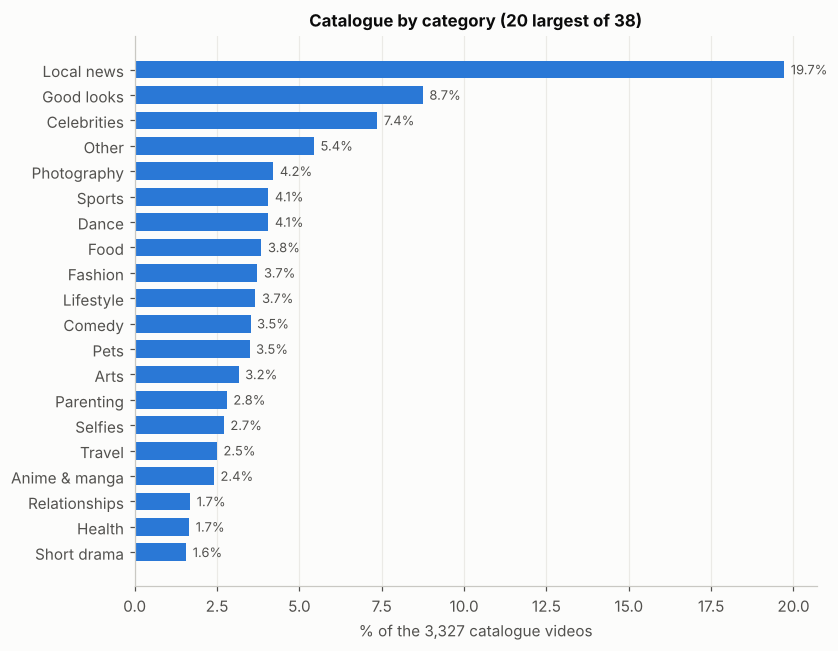

In [17]:
fig, ax = plt.subplots(figsize=(8, 6.5))
shown = cat_share.head(20)[::-1] * 100
ax.barh(shown.index, shown.values, color=FULL, height=0.7)
for i, v in enumerate(shown.values):
    ax.text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=8.5, color="#52514e")
ax.set(xlabel="% of the 3,327 catalogue videos",
       title=f"Catalogue by category (20 largest of {catalogue.category.nunique()})")
ax.grid(axis="y", visible=False)
save(fig, "01_catalogue_categories.png")

**Proposal: first-level category, "Other" and "Unknown" kept as categories of their own.**

- The catalogue is concentrated (Local news alone is about a fifth of it) but nowhere near the plan's 40% red flag. A random top 10 contains about 7.6 categories, so there's a lot of room for the Act 2 curve to fall, and a meaningful "random" reference line to draw on that chart.
- **Say in the report:** Local news is so large that a user who likes it will see a lot of it even from a perfectly *unbiased* recommender. Part of any collapse toward Local news is the catalogue, not the feedback loop. The random reference line is how we separate the two.
- **Caveat on "Other":** it's a catch-all. Two "Other" videos count as the same category even if they're unrelated, so diversity is slightly *under*-counted when "Other" shows up. It's 5% of the catalogue, small enough to mention as a limitation rather than fix.

## 6. Summary: proposed decisions for the team

These go into [`docs/02_decisions_log.md`](../docs/02_decisions_log.md) as **proposed**, until the team validates them.

| Decision | Proposed value | Evidence (this notebook) |
| --- | --- | --- |
| Outlier cap | **4.0**, on the model target only | ≈ p99 of train (4.29); caps 1.2% of rows; std 1.55 → 0.74 |
| Relevance threshold | **2.0** (fallback 1.5) | 4.7% of val rows relevant; median user has 83 liked videos; 1% of users have under 10 |
| Category | **First-level category**, "Other"/"Unknown" kept as is | One per video; first tags disagree for 1/3 of videos; largest category 19.7% |
| Sample representativeness | **OK** | TVD 0.036 (watch ratio), 0.043 (categories); fewer quick skips, explained by spec fix #1 |

**Open points for Phase 2:**

1. Evaluation users have thin training histories (section 2). If Act 1 is weak, raise `--train-rows` before blaming the model.
2. For Act 2, draw the **random top-10 line (~7.6 categories)** on the chart, next to the maximum of 10.